# Figure 2 -- the reported per-epoch uncertainty against the *Gaia* DR4 prerelease (`dr4_prerelease_medians_vs_g`)

Per-epoch along-scan uncertainty against $G$. Crosses are the 12 DR4 prerelease sources, their
per-CCD errors combined into one value per transit by an inverse-variance weighted mean and the
median taken; the two bands are the simulated stars' moving median and 16--84% range in $G$ of
$\sigma_{\rm UEVA,single}$ (the scatter the catalog injects) and of the median
$\sigma_{\rm reported}$ written to their epoch tables (the uncertainty it reports). The binned
version of the reported-uncertainty comparison is kept as a supplementary figure (Section 4).
Four of the twelve are fainter than the `G23H` limit of $G = 16$ and have no counterpart in the
model.

Inputs: the ESA DR4 prerelease VOTable (`analysis/data/dr4_prerelease/`), `stars.csv` for the
noise-model ingredients, `injected_solutions_0_companion.parquet` for the injected noise scale, and
the `0_companion` epoch shards for the reported uncertainties -- two columns of each, streamed off
the server once and cached (`paperfig.sigma_reported_cache`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

import paperfig as pf          # paths, style, loaders and the shared figure machinery

pf.setup_style()               # Computer Modern, usetex -- the paper's typography
print("catalog :", pf.CATALOG)
print("paper figures         :", pf.PAPER_FIG_DIR)
print("supplementary figures :", pf.SUPP_FIG_DIR)

catalog : /Users/daniel/Desktop/epochalypse_catalog/catalog
paper figures         : /Users/daniel/Desktop/epochalypse_catalog/analysis/paper_figures
supplementary figures : /Users/daniel/Desktop/epochalypse_catalog/analysis/supplementary_figures


## 1. The 12 prerelease sources

Names and groups from the ESA prerelease page: a **parallax** group (varying $G$ at
$\varpi \approx 1$ mas), a **magnitude** group ($G \approx 14$ at varying $\varpi$), three **QSOs**,
and an **orbit** group with real reflex motion.

In [2]:
from astropy.table import Table

PRERELEASE_XML = pf.EXTERNAL / "dr4_prerelease" / "GAIA_DR4_PRERELEASE_EPOCH_ASTROMETRY_RAW.xml"
TIME_ORIGIN_JD = 2455197.5           # VOTable TIMESYS: obs_time_tcb is ns since this JD (TCB)
NS_PER_DAY = 86_400e9
N_DOF = 5                            # five-parameter solutions, all 12 sources

SOURCE_INFO = {
    4181040337841125632: ("HD 183633", "parallax"),
    3926186255616949504: (None, "parallax"),
    435469040545191680: (None, "parallax"),
    1663617687609809280: ("LSPM J1324+6124", "magnitude"),
    2309425390592896: (None, "magnitude"),
    20694084440761600: (None, "magnitude"),
    2237987199365376: (None, "qso"),
    60730287810150016: (None, "qso"),
    10973744521070720: (None, "qso"),
    3937211745905473024: ("HD 114762", "orbit"),
    1457486023639239296: ("Gaia-4", "orbit"),
    4318465066420528000: ("Gaia BH3", "orbit"),
}
PUBLISHED_PLX = {
    4181040337841125632: 1.0, 3926186255616949504: 1.0, 435469040545191680: 1.0,
    1663617687609809280: 10.1, 2309425390592896: 0.9, 20694084440761600: 4.9,
    2237987199365376: 0.0, 60730287810150016: 0.0, 10973744521070720: 0.0,
    3937211745905473024: 25.6, 1457486023639239296: 13.6, 4318465066420528000: 2.0,
}


def label(sid):
    name, group = SOURCE_INFO[sid]
    return name if name else f"{group} {str(sid)[:6]}..."


def as_float_array(x):
    return np.ma.filled(np.ma.masked_invalid(np.atleast_1d(x).astype(float)), np.nan)


transits = Table.read(PRERELEASE_XML, format="votable").to_pandas()
print(f"{len(transits)} transit rows, {transits.source_id.nunique()} unique sources")

ccd_rows = []
for _, r in transits.iterrows():
    al, err = as_float_array(r.centroid_pos_al), as_float_array(r.centroid_pos_error_al)
    psi, tobs = as_float_array(r.scan_pos_angle), as_float_array(r.obs_time_tcb)
    used = np.atleast_1d(np.ma.filled(r.used_by_agis_al, False)).astype(bool)
    for k in range(len(al)):
        ccd_rows.append({"source_id": r.source_id, "transit_id": r.transit_id, "ccd": k,
                         "g_mag": float(r.g_mag), "jd_tcb": TIME_ORIGIN_JD + tobs[k] / NS_PER_DAY,
                         "scan_pos_angle": psi[k], "parallax_factor_al": float(r.parallax_factor_al),
                         "centroid_pos_al": al[k], "centroid_pos_error_al": err[k],
                         "used_by_agis_al": used[k]})
ccd = pd.DataFrame(ccd_rows)
ccd["group"] = ccd.source_id.map(lambda s: SOURCE_INFO[s][1])

# CCD index 0 is the sky-mapper window, never used by AGIS; keep what entered the solution
good = (ccd.used_by_agis_al & np.isfinite(ccd.centroid_pos_al) & np.isfinite(ccd.centroid_pos_error_al)
        & (ccd.centroid_pos_error_al > 0) & np.isfinite(ccd.scan_pos_angle)
        & np.isfinite(ccd.parallax_factor_al) & np.isfinite(ccd.jd_tcb))
ccd_ok = ccd[good].copy()
n_sm = int((ccd.ccd == 0).sum())
n_af_rejected = int(((ccd.ccd > 0) & ~ccd.used_by_agis_al).sum())
print(f"{len(ccd_ok)} / {len(ccd)} CCD observations retained ({100 * good.mean():.0f}%): "
      f"{n_sm} sky-mapper windows never flagged, {n_af_rejected} astrometric-field windows AGIS rejected "
      f"({100 * n_af_rejected / len(ccd):.0f}% of all, {100 * n_af_rejected / (len(ccd) - n_sm):.0f}% of AF)")
jd = ccd_ok.jd_tcb
print(f"time span: {(jd.max() - jd.min()) / 365.25:.2f} yr")

1008 transit rows, 12 unique sources


7467 / 10080 CCD observations retained (74%): 1008 sky-mapper windows never flagged, 1605 astrometric-field windows AGIS rejected (16% of all, 18% of AF)
time span: 5.26 yr


### Usable epochs in the prerelease

How much of the prerelease epoch data entered the astrometric solution. `used_by_agis_al` is defined
in the draft DR4 data model as "whether the CCD transit was used by AGIS-DR4 in AL direction", i.e.
an observation with non-zero AGIS weight. The like-for-like quantity for the catalog's 10% FoV-transit
loss is the fraction of *transits* with no AF window used at all; the CCD-level figures are given
alongside.

In [3]:
af = ccd[ccd.ccd > 0]                                            # astrometric-field windows only (SM never used)
per_transit = (af.groupby(["source_id", "transit_id"])
                 .agg(n_af=("used_by_agis_al", "size"), n_used=("used_by_agis_al", "sum"),
                      g_mag=("g_mag", "first"), group=("group", "first")).reset_index())
lost = per_transit.n_used == 0
n_t = len(per_transit)
print(f"{n_t} FoV transits, {len(af)} AF CCD windows, 12 sources")
print(f"transits with no AF window used by AGIS: {lost.sum()} / {n_t} = {100 * lost.mean():.1f}%  "
      f"-> {100 * (1 - lost.mean()):.1f}% of transits usable  (binomial 1-sigma {100 * np.sqrt(lost.mean() * (1 - lost.mean()) / n_t):.1f}%)")
print(f"used AF windows per transit: {per_transit.n_used.value_counts().sort_index().to_dict()}  "
      f"-- the loss is all-or-nothing: kept transits retain {100 * (per_transit.n_used / per_transit.n_af)[~lost].mean():.1f}% of their windows")
print(f"AF CCD windows used: {af.used_by_agis_al.sum()} / {len(af)} = {100 * af.used_by_agis_al.mean():.1f}%  "
      f"(all windows incl. SM: {ccd.used_by_agis_al.sum()} / {len(ccd)} = {100 * ccd.used_by_agis_al.mean():.1f}%)")

per_source = (per_transit.groupby("source_id")
                .agg(G=("g_mag", "first"), group=("group", "first"), n_transit=("n_used", "size"),
                     n_lost=("n_used", lambda x: int((x == 0).sum()))).reset_index())
per_source["source"] = per_source.source_id.map(label)
per_source["f_lost"] = per_source.n_lost / per_source.n_transit
per_source["f_usable"] = 1 - per_source.f_lost
per_source = per_source.sort_values("G")
print("\nper source:")
print(per_source[["source", "group", "G", "n_transit", "n_lost", "f_lost", "f_usable"]]
      .to_string(index=False, float_format=lambda x: f"{x:.3f}"))
f = per_source.f_lost.to_numpy()
print(f"\nper-source transit loss: median {100 * np.median(f):.1f}%, range {100 * f.min():.1f}-{100 * f.max():.1f}%, mean {100 * f.mean():.1f}%")
f16 = per_source[per_source.G <= 16].f_lost.to_numpy()
print(f"  G <= 16 (n={len(f16)}): median {100 * np.median(f16):.1f}%, range {100 * f16.min():.1f}-{100 * f16.max():.1f}%")
f14 = per_source[(per_source.G > 13.5) & (per_source.G < 14.5)].f_lost.to_numpy()
print(f"  G ~ 14 (n={len(f14)}): median {100 * np.median(f14):.1f}%, range {100 * f14.min():.1f}-{100 * f14.max():.1f}%")
print(f"  catalog assumption: 10% of FoV transits lost per target")


1008 FoV transits, 9072 AF CCD windows, 12 sources
transits with no AF window used by AGIS: 158 / 1008 = 15.7%  -> 84.3% of transits usable  (binomial 1-sigma 1.1%)
used AF windows per transit: {0: 158, 5: 1, 6: 4, 7: 10, 8: 147, 9: 688}  -- the loss is all-or-nothing: kept transits retain 97.6% of their windows
AF CCD windows used: 7467 / 9072 = 82.3%  (all windows incl. SM: 7467 / 10080 = 74.1%)

per source:
             source     group      G  n_transit  n_lost  f_lost  f_usable
          HD 114762     orbit  7.152         90      27   0.300     0.700
          HD 183633  parallax  8.975         97      25   0.258     0.742
           Gaia BH3     orbit 11.231         77      14   0.182     0.818
             Gaia-4     orbit 11.909        115      22   0.191     0.809
 parallax 435469...  parallax 13.973         81       7   0.086     0.914
magnitude 230942... magnitude 14.014         75       7   0.093     0.907
magnitude 206940... magnitude 14.046         74       9   0.122     

## 2. Per-transit combination and the five-parameter fit

Those sharing a `transit_id` are combined into one epoch by an inverse-variance weighted mean,
$\sigma^{\rm DR4}_{\rm formal} = (\sum_i \sigma_i^{-2})^{-1/2}$ -- the same construction as the
catalog's $\sigma_{\rm formal}$. The five-parameter fit uses the generator's own design matrix;
the fitted parallaxes reproduce the published ones for every source without an orbit, and the three
orbit sources show the reflex motion the model cannot absorb.

In [4]:
def combine_transits(df_source):
    out = []
    for tid, t in df_source.groupby("transit_id"):
        if len(t) < 3:
            continue
        w = 1.0 / t.centroid_pos_error_al.to_numpy() ** 2
        al = t.centroid_pos_al.to_numpy()
        out.append({"transit_id": tid, "jd_tcb": t.jd_tcb.mean(),
                    "scan_pos_angle": np.radians(t.scan_pos_angle.mean()),
                    "parallax_factor_al": t.parallax_factor_al.iloc[0],
                    "centroid_pos_al": np.sum(w * al) / np.sum(w),
                    "centroid_pos_error_al": 1.0 / np.sqrt(np.sum(w)),
                    "n_ccd": len(t), "ccd_err_median": np.median(t.centroid_pos_error_al)})
    return pd.DataFrame(out).sort_values("jd_tcb").reset_index(drop=True)


fov = {sid: combine_transits(d) for sid, d in ccd_ok.groupby("source_id")}
print(f"per-FoV-transit epochs for {len(fov)} sources; N_FoV = {min(len(v) for v in fov.values())}-"
      f"{max(len(v) for v in fov.values())}")

fits = {}
for sid, ep in fov.items():
    t = (ep.jd_tcb.to_numpy() - pf.K.GAIA_EPOCH_TCB_JD) / pf.YR
    psi, pfac = ep.scan_pos_angle.to_numpy(), ep.parallax_factor_al.to_numpy()
    y, yerr = ep.centroid_pos_al.to_numpy(), ep.centroid_pos_error_al.to_numpy()
    beta, cov, X = pf.weighted_linear_solution(t, psi, pfac, y, yerr)
    resid = y - X @ beta
    fits[sid] = {"n_fov": len(y), "parallax": beta[4],
                 "chi2_red": np.sum((resid / yerr) ** 2) / (len(y) - N_DOF),
                 "sigma_formal": np.median(yerr), "ccd_err": np.median(ep.ccd_err_median),
                 "g_mag": ccd_ok[ccd_ok.source_id == sid].g_mag.iloc[0]}

chk = pd.DataFrame([{"source": label(s), "group": SOURCE_INFO[s][1], "G": f["g_mag"], "N_FoV": f["n_fov"],
                     "plx_fit": f["parallax"], "plx_published": PUBLISHED_PLX[s], "chi2_red": f["chi2_red"],
                     "sigma_formal_DR4 [mas]": f["sigma_formal"]} for s, f in fits.items()]).sort_values("G")
print(chk.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

per-FoV-transit epochs for 12 sources; N_FoV = 54-93
             source     group      G  N_FoV  plx_fit  plx_published  chi2_red  sigma_formal_DR4 [mas]
          HD 114762     orbit  7.152     63   25.645         25.600   929.719                   0.042
          HD 183633  parallax  8.975     72    1.001          1.000     0.957                   0.035
           Gaia BH3     orbit 11.231     63    0.983          2.000 63402.990                   0.028
             Gaia-4     orbit 11.909     93   13.621         13.600    21.109                   0.028
 parallax 435469...  parallax 13.973     74    0.998          1.000     1.322                   0.048
magnitude 230942... magnitude 14.014     68    0.927          0.900     0.857                   0.049
magnitude 206940... magnitude 14.046     65    4.942          4.900     1.410                   0.050
    LSPM J1324+6124 magnitude 14.255     89   10.105         10.100     1.203                   0.054
 parallax 392618...  parallax

### Epoch-to-epoch variation of the uncertainty

The catalog perturbs every epoch's uncertainty by a zero-mean 10% fractional jitter,
$\sigma_i = (1 + 0.1\,\xi_i)\,\sigma$ with $\xi_i \sim \mathcal{N}(0,1)$. The like-for-like
quantity in the prerelease is the scatter of a source's per-transit $\sigma^{\rm DR4}_{\rm formal}$
about its own median, as a fraction of that median; the MAD-based version guards against a few
outlying transits. The last two columns split the scatter into the part carried by the per-CCD
errors and the part carried by how many CCD windows were combined ($\propto 1/\sqrt{n_{\rm CCD}}$).

In [5]:
# epoch-to-epoch variation of the per-transit uncertainty within each source: the empirical
# counterpart of the catalog's 10% fractional jitter, sigma_i = (1 + 0.1 xi_i) sigma
def _mad(x):
    return 1.4826 * np.median(np.abs(x - np.median(x)))


rows = []
for sid, ep in fov.items():
    s = ep.centroid_pos_error_al.to_numpy()          # inverse-variance combined, one per transit
    c = ep.ccd_err_median.to_numpy()                 # median per-CCD error of that transit
    r = 1.0 / np.sqrt(ep.n_ccd.to_numpy())           # the part due to how many CCDs were combined
    rows.append({"source": label(sid), "group": SOURCE_INFO[sid][1], "G": fits[sid]["g_mag"],
                 "N_FoV": len(s), "median_sigma [mas]": np.median(s),
                 "frac_std": np.std(s) / np.median(s), "frac_mad": _mad(s) / np.median(s),
                 "frac_std_ccd_err": np.std(c) / np.median(c), "frac_std_n_ccd": np.std(r) / np.median(r)})
jit = pd.DataFrame(rows).sort_values("G")
print("fractional epoch-to-epoch scatter of the per-transit uncertainty, per source:")
print(jit.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

j16 = jit[jit.G <= 16]
print(f"\nall 12 sources: frac_std median {jit.frac_std.median():.3f}, range {jit.frac_std.min():.3f}-{jit.frac_std.max():.3f}"
      f"  (MAD-based: median {jit.frac_mad.median():.3f}, range {jit.frac_mad.min():.3f}-{jit.frac_mad.max():.3f})")
print(f"G <= 16 (n={len(j16)}): frac_std median {j16.frac_std.median():.3f}, range {j16.frac_std.min():.3f}-{j16.frac_std.max():.3f}"
      f"  (MAD-based: median {j16.frac_mad.median():.3f}, range {j16.frac_mad.min():.3f}-{j16.frac_mad.max():.3f})")
for name, sel in (("G < 12", j16.G < 12), ("G ~ 14", (j16.G > 13.5) & (j16.G < 14.5))):
    s = j16[sel]
    print(f"  {name} (n={len(s)}): frac_std {s.frac_std.min():.3f}-{s.frac_std.max():.3f}")
print(f"the scatter is in the per-CCD errors, not the CCD count: n_ccd alone gives "
      f"{j16.frac_std_n_ccd.min():.3f}-{j16.frac_std_n_ccd.max():.3f} at G <= 16")
print("catalog assumption: 10% fractional jitter per epoch, the same for injected and reported sigma")

fractional epoch-to-epoch scatter of the per-transit uncertainty, per source:
             source     group      G  N_FoV  median_sigma [mas]  frac_std  frac_mad  frac_std_ccd_err  frac_std_n_ccd
          HD 114762     orbit  7.152     63               0.042     0.076     0.080             0.070           0.021
          HD 183633  parallax  8.975     72               0.035     0.177     0.152             0.209           0.022
           Gaia BH3     orbit 11.231     63               0.028     0.216     0.230             0.205           0.025
             Gaia-4     orbit 11.909     93               0.028     0.150     0.135             0.149           0.021
 parallax 435469...  parallax 13.973     74               0.048     0.068     0.051             0.054           0.026
magnitude 230942... magnitude 14.014     68               0.049     0.054     0.051             0.033           0.037
magnitude 206940... magnitude 14.046     65               0.050     0.044     0.047             

## 3. The model: every simulated star

The simulated stars (the control population's truth table, which carries the injected noise scale
`sigma_single_mas`) joined to the noise-model ingredients in `stars.csv`. Two quantities per star:

$$\sigma_{\rm formal} = \sqrt{\frac{\sigma_{\rm att}^2+\sigma_{\rm AL}^2}{\langle N_{\rm AL}\rangle}},
\qquad
\sigma_{\rm UEVA,single} = \sqrt{\frac{(N_{\rm FoV}-n_{\rm dof})\,\sigma_{\rm cal}^2 + N_{\rm FoV}\,\sigma_{\rm AL}^2}{N_{\rm AL}-n_{\rm dof}}},$$

the second rebuilt here and checked against the value the run injected. What the catalog *writes*
is $\sigma_{{\rm reported},i} = (1+0.1\,\xi_i)\,\sigma_{\rm formal}$ per epoch; the figure uses the
median of that over each star's epochs, read off the epoch shards, so it is a statement about what a
user of the catalog sees.

In [6]:
stars = pf.star_columns()
truths = pd.read_parquet(pf.C.truths("0_companion"), columns=["gaia_source_id", "sigma_single_mas", "n_transits_dr4"])
truths["gaia_source_id"] = truths.gaia_source_id.astype("int64")
sample = truths.merge(stars, on="gaia_source_id", how="left")
assert sample["sig_AL"].notna().all() and sample["sig_att_radec"].notna().all()
print(f"simulated by the run: {len(sample):,} stars; G {sample.phot_g_mean_mag_dr3.min():.2f}-"
      f"{sample.phot_g_mean_mag_dr3.max():.2f}; DR4 transits median {sample.n_transits_dr4.median():.0f}")

model = sample.copy()
ueva, formal = pf.noise_terms(model)
model["sigma_formal"] = formal
model["sigma_ccd"] = np.hypot(model.sig_att_radec, model.sig_AL)
model["sigma_ueva"] = model.sigma_single_mas
print(f"analytic sigma_UEVA,single vs the run's sigma_single_mas: max fractional difference "
      f"{np.nanmax(np.abs(ueva / model.sigma_ueva - 1)):.1e}")
model["inflation"] = model.sigma_ueva / model.sigma_formal
print(f"UEVA inflation sigma_UEVA/sigma_formal: median {model.inflation.median():.3f}, "
      f"16-84% {model.inflation.quantile(0.16):.3f}-{model.inflation.quantile(0.84):.3f}")

# the reported uncertainty the catalog actually ships, per star, off the epoch shards
rep = pf.sigma_reported_cache("0_companion")
model = model.merge(rep, on="gaia_source_id", how="left")
assert model.sigma_reported_med.notna().all()
_r = model.sigma_reported_med / model.sigma_formal
print(f"median sigma_reported (epoch tables) / analytic sigma_formal: {_r.median():.4f} "
      f"[16-84% {_r.quantile(0.16):.4f}-{_r.quantile(0.84):.4f}]  -- the jitter is zero-mean")

# moving-window estimators in G
_LOCUS_COLS = ["sigma_ccd", "sigma_formal", "sigma_reported_med", "inflation"]
_order = np.argsort(model.phot_g_mean_mag_dr3.to_numpy())
_G_SORTED = model.phot_g_mean_mag_dr3.to_numpy()[_order]
_SORTED = {c: model[c].to_numpy()[_order] for c in _LOCUS_COLS}


def _window(g, half_width=0.25, min_n=60, max_half_width=1.0):
    hw = half_width
    while True:
        lo, hi = np.searchsorted(_G_SORTED, [g - hw, g + hw])
        if hi - lo >= min_n or hw >= max_half_width:
            return int(lo), int(hi)
        hw = min(hw * 1.5, max_half_width)


def model_at(col, g, **kw):
    lo, hi = _window(g, **kw)
    return float(np.median(_SORTED[col][lo:hi]))


def model_percentile(col, g, value, **kw):
    lo, hi = _window(g, **kw)
    return 100.0 * float(np.mean(_SORTED[col][lo:hi] < value))


def locus(col, grid=None, **kw):
    grid = np.arange(3.2, 16.001, 0.05) if grid is None else grid
    med, lo_, hi_ = [], [], []
    for g in grid:
        lo, hi = _window(g, **kw)
        v = _SORTED[col][lo:hi]
        med.append(np.median(v)); lo_.append(np.quantile(v, 0.16)); hi_.append(np.quantile(v, 0.84))
    return grid, np.array(med), np.array(lo_), np.array(hi_)


overlap = sorted(set(ccd_ok.source_id) & set(sample.gaia_source_id))
print(f"\nprerelease sources that are simulated stars of this catalog: {len(overlap)}: "
      + ", ".join(label(s) for s in overlap))
G_MAX = sample.phot_g_mean_mag_dr3.max()
print(f"{sum(f['g_mag'] <= G_MAX for f in fits.values())} of 12 fall inside the run's magnitude range (G <= {G_MAX:.1f})")

simulated by the run: 5,040,328 stars; G 3.47-16.00; DR4 transits median 81


analytic sigma_UEVA,single vs the run's sigma_single_mas: max fractional difference 1.6e-15
UEVA inflation sigma_UEVA/sigma_formal: median 1.005, 16-84% 0.982-1.319


median sigma_reported (epoch tables) / analytic sigma_formal: 1.0000 [16-84% 0.9864-1.0136]  -- the jitter is zero-mean



prerelease sources that are simulated stars of this catalog: 3: magnitude 206940..., Gaia-4, HD 114762
8 of 12 fall inside the run's magnitude range (G <= 16.0)


### The comparison as a scatter

Every simulated star as a point, the 12 prerelease sources as crosses, the moving median in $G$.
At 5 M stars the cloud saturates into a slab, which is why the paper version bins it instead.

  wrote analysis/supplementary_figures/dr4_prerelease_sigma_vs_g_single.pdf, analysis/supplementary_figures/dr4_prerelease_sigma_vs_g_single.png


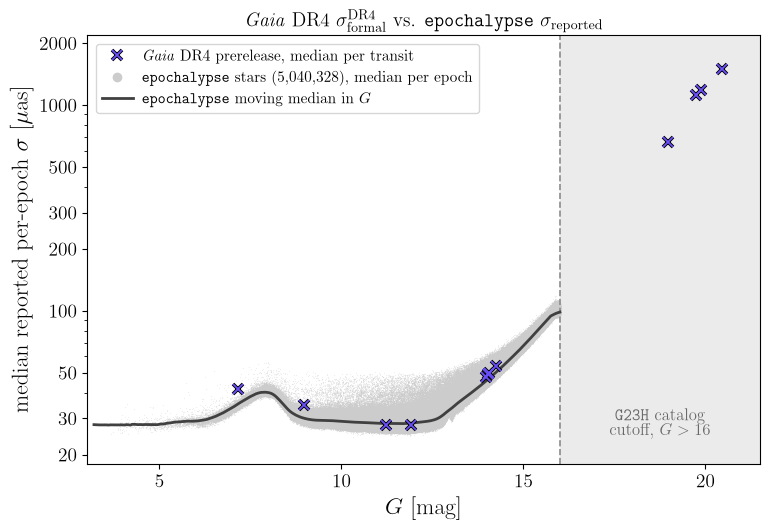

In [7]:
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple

DR4_COLOR = "#6A50FA"
FS_TITLE, FS_LABEL, FS_TICK, FS_LEGEND, FS_NOTE = 14, 17, 14, 12, 12
UAS = 1e3
dr4_g = np.array([f["g_mag"] for f in fits.values()])
dr4_sigma = np.array([f["sigma_formal"] for f in fits.values()]) * UAS
marker_kw = dict(marker="x", ms=7, ls="none")
_yt = [20, 30, 50, 100, 200, 300, 500, 1000, 2000]


def dress(ax):
    ax.axvspan(16, 21.5, color="0.92", zorder=0)
    ax.axvline(16, color="0.55", lw=1.2, ls="--", zorder=1)
    ax.set_yscale("log")
    ax.set_ylim(18, 2200)
    ax.set_yticks(_yt)
    ax.set_yticklabels([str(v) for v in _yt])
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.text(18.75, 0.06, r"\texttt{G23H} catalog" "\n" r"cutoff, $G > 16$",
            transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=FS_NOTE,
            color="0.40", linespacing=1.4)
    ax.set_xlabel("$G$ [mag]", fontsize=FS_LABEL)
    ax.set_ylabel(r"median reported per-epoch $\sigma$ [$\mu$as]", fontsize=FS_LABEL)
    ax.set_xlim(3, 21.5)
    ax.set_xticks([5, 10, 15, 20])
    ax.tick_params(which="both", labelsize=FS_TICK)
    ax.set_title(r"\textit{Gaia} DR4 $\sigma_{\rm formal}^{\rm DR4}$ vs. "
                 r"\texttt{epochalypse} $\sigma_{\rm reported}$", fontsize=FS_TITLE)


fig, ax = plt.subplots(figsize=(7.8, 5.4))
ax.scatter(model.phot_g_mean_mag_dr3, model.sigma_reported_med * UAS, s=0.6, color="0.80", alpha=0.35,
           linewidths=0, rasterized=True)
gc, med, lo, hi = locus("sigma_reported_med")
ax.plot(gc, med * UAS, color="0.25", lw=2, zorder=3)
ax.plot(dr4_g, dr4_sigma, **marker_kw, mec="k", mew=2.6, zorder=5)
ax.plot(dr4_g, dr4_sigma, **marker_kw, mec=DR4_COLOR, mew=1.3, zorder=6)
dress(ax)
dr4_key = (Line2D([0], [0], **marker_kw, mec="k", mew=2.6), Line2D([0], [0], **marker_kw, mec=DR4_COLOR, mew=1.3))
handles = [dr4_key, Line2D([0], [0], marker="o", color="0.80", ls="none", ms=6), Line2D([0], [0], color="0.25", lw=2)]
labels = [r"\textit{Gaia} DR4 prerelease, median per transit",
          rf"\texttt{{epochalypse}} stars ({pf.tex_num(len(model))}), median per epoch",
          r"\texttt{epochalypse} moving median in $G$"]
ax.legend(handles=handles, labels=labels, loc="upper left", ncol=1, fontsize=FS_LEGEND - 1,
          handler_map={tuple: HandlerTuple(ndivide=1, pad=0)}, handletextpad=0.6, labelspacing=0.45, borderaxespad=0.6)
fig.tight_layout()
pf.save(fig, "dr4_prerelease_sigma_vs_g_single", dpi=150)
plt.show()

## 4. The reported uncertainty, binned (supplementary)

The same axes with the cloud binned: uniform in $G$ (0.05 mag) and in $\log\sigma$ ($\sim$0.012
dex), the per-bin count on a log colour scale, empty bins left unpainted.

2D histogram: 5,040,328 stars in 3,811 occupied bins; densest bin holds 40,813


  wrote analysis/supplementary_figures/dr4_prerelease_sigma_vs_g_single_hist2d.pdf, analysis/supplementary_figures/dr4_prerelease_sigma_vs_g_single_hist2d.png


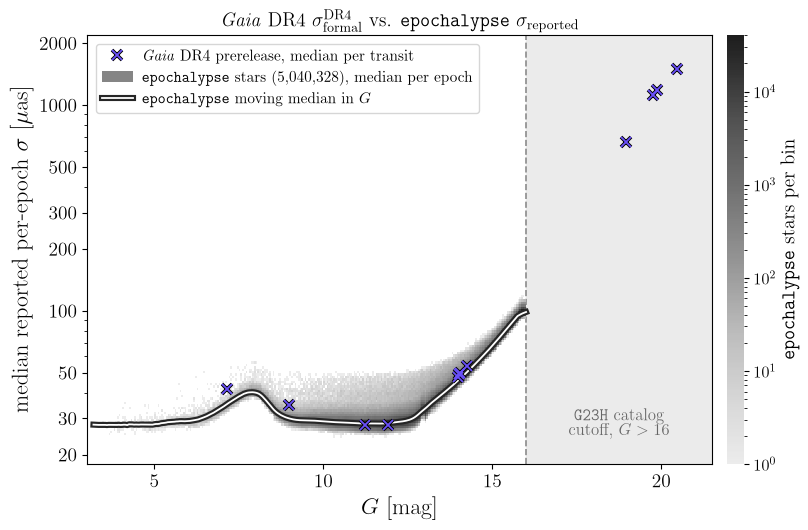

In [8]:
from matplotlib.colors import LogNorm, ListedColormap
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

DENSITY_CMAP = ListedColormap(plt.get_cmap("Greys")(np.linspace(0.15, 0.90, 256)), name="Greys_trimmed")

fig, ax = plt.subplots(figsize=(8.6, 5.4))
_hg = model.phot_g_mean_mag_dr3.to_numpy()
_hs = model.sigma_reported_med.to_numpy() * UAS
_ok = np.isfinite(_hg) & np.isfinite(_hs)
_xedges = np.linspace(3.0, 16.0, 261)                      # 0.05 mag
_yedges = np.logspace(np.log10(18), np.log10(2200), 181)   # ~0.0116 dex
_counts, _, _, _im = ax.hist2d(_hg[_ok], _hs[_ok], bins=[_xedges, _yedges], cmin=1, norm=LogNorm(vmin=1),
                               cmap=DENSITY_CMAP, rasterized=True, zorder=2)
print(f"2D histogram: {_ok.sum():,} stars in {(_counts > 0).sum():,} occupied bins; densest bin holds {int(np.nanmax(_counts)):,}")
cb = fig.colorbar(_im, ax=ax, pad=0.02, aspect=26)
cb.set_label(r"\texttt{epochalypse} stars per bin", fontsize=FS_LABEL - 3)
cb.ax.tick_params(labelsize=FS_TICK - 2)
cb.outline.set_visible(False)

gc, med, lo, hi = locus("sigma_reported_med")
_median_kw = dict(color="w", lw=1.3, path_effects=[pe.Stroke(linewidth=4.4, foreground="0.15"), pe.Normal()])
ax.plot(gc, med * UAS, zorder=4, **_median_kw)
ax.plot(dr4_g, dr4_sigma, **marker_kw, mec="k", mew=2.6, zorder=5)
ax.plot(dr4_g, dr4_sigma, **marker_kw, mec=DR4_COLOR, mew=1.3, zorder=6)
dress(ax)
handles = [dr4_key, Patch(facecolor=DENSITY_CMAP(0.55), edgecolor="none"), Line2D([0], [0], **_median_kw)]
ax.legend(handles=handles, labels=labels, loc="upper left", ncol=1, fontsize=FS_LEGEND - 1,
          handler_map={tuple: HandlerTuple(ndivide=1, pad=0)}, handletextpad=0.6, labelspacing=0.45, borderaxespad=0.6)
fig.tight_layout()
pf.save(fig, "dr4_prerelease_sigma_vs_g_single_hist2d", dpi=150)
plt.show()

### Numbers for the text

The ratio of each source's DR4 per-transit uncertainty to the model's moving median at its
magnitude, and where it falls in the model's star-to-star spread.

In [9]:
rows = []
for sid, f in fits.items():
    in_range = f["g_mag"] <= G_MAX
    rows.append({"source": label(sid), "group": SOURCE_INFO[sid][1], "G": f["g_mag"],
                 "ccd_dr4": f["ccd_err"], "ccd_model": model_at("sigma_ccd", f["g_mag"]) if in_range else np.nan,
                 "formal_dr4": f["sigma_formal"],
                 "formal_model": model_at("sigma_reported_med", f["g_mag"]) if in_range else np.nan,
                 "pctile": model_percentile("sigma_reported_med", f["g_mag"], f["sigma_formal"]) if in_range else np.nan})
cmp_sigma = pd.DataFrame(rows).sort_values("G")
cmp_sigma["ratio_ccd"] = cmp_sigma.ccd_dr4 / cmp_sigma.ccd_model
cmp_sigma["ratio_formal"] = cmp_sigma.formal_dr4 / cmp_sigma.formal_model
print(cmp_sigma.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

inr = cmp_sigma.dropna(subset=["ratio_formal"])
print(f"\nin-range sources (n={len(inr)}): median DR4/model per-epoch = {inr.ratio_formal.median():.3f}"
      f"  [{inr.ratio_formal.min():.3f}-{inr.ratio_formal.max():.3f}]")
for name, sel in (("G <= 10", inr.G <= 10), ("G > 10", inr.G > 10)):
    s = inr[sel]
    print(f"  {name} (n={len(s)}): median {s.ratio_formal.median():.3f}, "
          f"span {s.ratio_formal.min():.3f}-{s.ratio_formal.max():.3f}, "
          f"percentiles {s.pctile.min():.0f}-{s.pctile.max():.0f}%")
print(f"\nstars with G <= 9 in the run: {int((model.phot_g_mean_mag_dr3 <= 9).sum()):,} "
      f"({100 * (model.phot_g_mean_mag_dr3 <= 9).mean():.1f}%)")

             source     group       G  ccd_dr4  ccd_model  formal_dr4  formal_model  pctile  ratio_ccd  ratio_formal
          HD 114762     orbit  7.1519   0.1236     0.1044      0.0418        0.0352 99.4683     1.1837        1.1874
          HD 183633  parallax  8.9747   0.1040     0.0887      0.0348        0.0300 98.5490     1.1724        1.1575
           Gaia BH3     orbit 11.2311   0.0830     0.0834      0.0279        0.0283 32.2511     0.9956        0.9848
             Gaia-4     orbit 11.9088   0.0823     0.0837      0.0279        0.0284 28.3845     0.9825        0.9808
 parallax 435469...  parallax 13.9734   0.1376     0.1342      0.0477        0.0456 76.1726     1.0261        1.0468
magnitude 230942... magnitude 14.0135   0.1416     0.1360      0.0490        0.0462 82.9847     1.0412        1.0605
magnitude 206940... magnitude 14.0463   0.1449     0.1376      0.0500        0.0468 86.7817     1.0533        1.0692
    LSPM J1324+6124 magnitude 14.2553   0.1561     0.1483      0

## 5. The injected scatter, $\sigma_{\rm UEVA,single}$, against the prerelease residual scatter

The paper figure compares what the catalog *reports*. This one compares what it *injects*: the
greyscale bins the simulated stars by $\sigma_{\rm UEVA,single}$ (Equation~\ref{eq:sigma_UEVA_single}
of the paper -- the calibration and AL terms, with no attitude term), and the crosses are the
empirical per-epoch scatter of the prerelease sources, the regression standard error of the
five-parameter fit of Section 2, $\sqrt{\sum_i r_i^2 / (N_{\rm FoV} - 5)}$, which is the quantity
${\rm UEVA}_{\rm single}$ is meant to predict for a single star. The three orbit sources are left
off the scatter marker (their residuals are reflex motion, not noise) but keep their formal
uncertainty cross. The question: is the bright-star degradation of $\sigma_{\rm cal}$ visible, and
does it match the two bright prerelease stars?

  wrote analysis/supplementary_figures/dr4_prerelease_ueva_vs_g_hist2d.pdf, analysis/supplementary_figures/dr4_prerelease_ueva_vs_g_hist2d.png


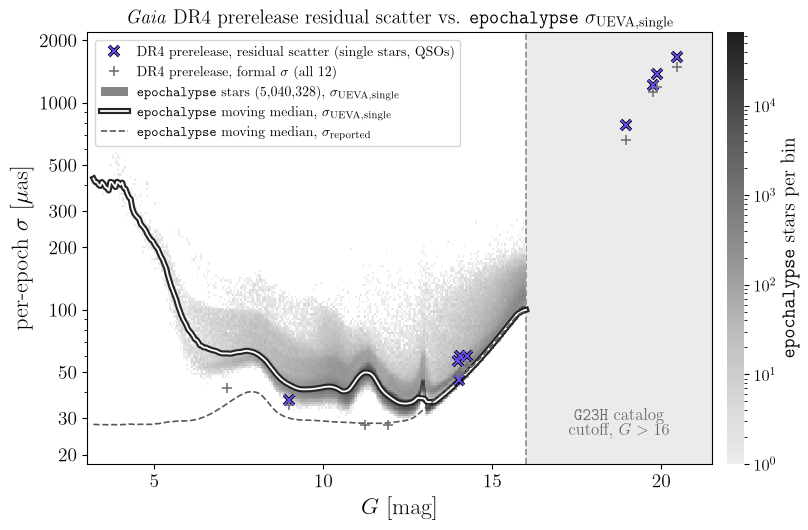

model sigma_UEVA,single moving median [uas] (and the UEVA/formal inflation):
  G =  7.0:   61.6 uas   formal   33.8 uas   inflation 1.838
  G =  8.0:   61.8 uas   formal   40.0 uas   inflation 1.551
  G =  9.0:   43.4 uas   formal   30.0 uas   inflation 1.453
  G = 10.0:   42.3 uas   formal   29.0 uas   inflation 1.465
  G = 11.0:   46.4 uas   formal   28.4 uas   inflation 1.634
  G = 12.0:   37.6 uas   formal   28.5 uas   inflation 1.314
  G = 13.0:   37.2 uas   formal   33.3 uas   inflation 1.180
  G = 14.0:   45.1 uas   formal   46.0 uas   inflation 0.981
  G = 15.0:   67.7 uas   formal   67.6 uas   inflation 0.999
  G = 16.0:  100.0 uas   formal   98.6 uas   inflation 1.010

prerelease residual scatter (regression standard error, mas) against the model's sigma_UEVA,single at that G;
orbit sources' scatter is reflex motion, not noise:
             source     group       G  scatter_dr4  scatter_mad  formal_dr4  ueva_model   pctile    ratio  scatter/formal
          HD 114762     orbi

In [10]:
# the model's injected scatter per star, and its moving median in G
_SORTED["sigma_ueva"] = model["sigma_ueva"].to_numpy()[_order]
_LOCUS_COLS.append("sigma_ueva")

# empirical per-epoch scatter of each prerelease source from the Section-2 five-parameter fit
emp = {}
for sid, ep in fov.items():
    t = (ep.jd_tcb.to_numpy() - pf.K.GAIA_EPOCH_TCB_JD) / pf.YR
    psi, pfac = ep.scan_pos_angle.to_numpy(), ep.parallax_factor_al.to_numpy()
    y, yerr = ep.centroid_pos_al.to_numpy(), ep.centroid_pos_error_al.to_numpy()
    beta, cov, X = pf.weighted_linear_solution(t, psi, pfac, y, yerr)
    resid = y - X @ beta
    emp[sid] = {"rse": np.sqrt(np.sum(resid**2) / (len(y) - N_DOF)),          # regression standard error
                "mad": 1.4826 * np.median(np.abs(resid - np.median(resid))),   # robust alternative
                "g_mag": fits[sid]["g_mag"], "orbit": SOURCE_INFO[sid][1] == "orbit"}

single = {s: e for s, e in emp.items() if not e["orbit"]}
emp_g = np.array([e["g_mag"] for e in single.values()])
emp_s = np.array([e["rse"] for e in single.values()]) * UAS
orb_g = np.array([e["g_mag"] for e in emp.values() if e["orbit"]])
orb_formal = np.array([fits[s]["sigma_formal"] for s, e in emp.items() if e["orbit"]]) * UAS

fig, ax = plt.subplots(figsize=(8.6, 5.4))
_hu = model.sigma_ueva.to_numpy() * UAS
_oku = np.isfinite(_hg) & np.isfinite(_hu)
_cu, _, _, _imu = ax.hist2d(_hg[_oku], _hu[_oku], bins=[_xedges, _yedges], cmin=1, norm=LogNorm(vmin=1),
                            cmap=DENSITY_CMAP, rasterized=True, zorder=2)
cb = fig.colorbar(_imu, ax=ax, pad=0.02, aspect=26)
cb.set_label(r"\texttt{epochalypse} stars per bin", fontsize=FS_LABEL - 3)
cb.ax.tick_params(labelsize=FS_TICK - 2)
cb.outline.set_visible(False)
gcu, medu, _, _ = locus("sigma_ueva")
ax.plot(gcu, medu * UAS, zorder=4, **_median_kw)
gcf, medf, _, _ = locus("sigma_reported_med")
ax.plot(gcf, medf * UAS, color="0.35", lw=1.2, ls="--", zorder=4)
# prerelease: empirical scatter (single-star sources) and formal uncertainty (all 12) for reference
ax.plot(emp_g, emp_s, **marker_kw, mec="k", mew=2.6, zorder=5)
ax.plot(emp_g, emp_s, **marker_kw, mec=DR4_COLOR, mew=1.3, zorder=6)
ax.plot(dr4_g, dr4_sigma, marker="+", ms=7, ls="none", mec="0.45", mew=1.2, zorder=5)
dress(ax)
ax.set_ylabel(r"per-epoch $\sigma$ [$\mu$as]", fontsize=FS_LABEL)
ax.set_title(r"\textit{Gaia} DR4 prerelease residual scatter vs. "
             r"\texttt{epochalypse} $\sigma_{\rm UEVA,single}$", fontsize=FS_TITLE)
handles = [dr4_key, Line2D([0], [0], marker="+", ms=7, ls="none", mec="0.45", mew=1.2),
           Patch(facecolor=DENSITY_CMAP(0.55), edgecolor="none"), Line2D([0], [0], **_median_kw),
           Line2D([0], [0], color="0.35", lw=1.2, ls="--")]
labels = [r"DR4 prerelease, residual scatter (single stars, QSOs)",
          r"DR4 prerelease, formal $\sigma$ (all 12)",
          rf"\texttt{{epochalypse}} stars ({pf.tex_num(len(model))}), $\sigma_{{\rm UEVA,single}}$",
          r"\texttt{epochalypse} moving median, $\sigma_{\rm UEVA,single}$",
          r"\texttt{epochalypse} moving median, $\sigma_{\rm reported}$"]
ax.legend(handles=handles, labels=labels, loc="upper left", ncol=1, fontsize=FS_LEGEND - 2,
          handler_map={tuple: HandlerTuple(ndivide=1, pad=0)}, handletextpad=0.6, labelspacing=0.45, borderaxespad=0.6)
fig.tight_layout()
pf.save(fig, "dr4_prerelease_ueva_vs_g_hist2d", dpi=150)
plt.show()

# numbers: the bright-star degradation in the model, and the prerelease scatter against it
print("model sigma_UEVA,single moving median [uas] (and the UEVA/formal inflation):")
for g in (7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0):
    print(f"  G = {g:4.1f}: {model_at('sigma_ueva', g) * UAS:6.1f} uas   "
          f"formal {model_at('sigma_reported_med', g) * UAS:6.1f} uas   inflation {model_at('inflation', g):.3f}")
rows = []
for sid, e in emp.items():
    in_range = e["g_mag"] <= G_MAX
    rows.append({"source": label(sid), "group": SOURCE_INFO[sid][1], "G": e["g_mag"],
                 "scatter_dr4": e["rse"], "scatter_mad": e["mad"], "formal_dr4": fits[sid]["sigma_formal"],
                 "ueva_model": model_at("sigma_ueva", e["g_mag"]) if in_range else np.nan,
                 "pctile": model_percentile("sigma_ueva", e["g_mag"], e["rse"]) if in_range else np.nan})
cmp_ueva = pd.DataFrame(rows).sort_values("G")
cmp_ueva["ratio"] = cmp_ueva.scatter_dr4 / cmp_ueva.ueva_model
cmp_ueva["scatter/formal"] = cmp_ueva.scatter_dr4 / cmp_ueva.formal_dr4
print("\nprerelease residual scatter (regression standard error, mas) against the model's sigma_UEVA,single at that G;")
print("orbit sources' scatter is reflex motion, not noise:")
print(cmp_ueva.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
ok = cmp_ueva[(cmp_ueva.group != "orbit") & cmp_ueva.ratio.notna()]
print(f"\nsingle-star sources in range (n={len(ok)}): median scatter/model = {ok.ratio.median():.3f} "
      f"[{ok.ratio.min():.3f}-{ok.ratio.max():.3f}]")
for name, sel in (("G <= 10", ok.G <= 10), ("G > 10", ok.G > 10)):
    s = ok[sel]
    if len(s):
        print(f"  {name} (n={len(s)}): scatter/model {s.ratio.min():.3f}-{s.ratio.max():.3f}, "
              f"percentiles {s.pctile.min():.0f}-{s.pctile.max():.0f}%, scatter/formal {s['scatter/formal'].min():.3f}-{s['scatter/formal'].max():.3f}")


### The paper figure: the two medians

The same comparison stripped to its lines: the moving median of $\sigma_{\rm UEVA,single}$ (what the
catalog injects), the moving median of $\sigma_{\rm reported}$ (what it reports), and the 12
prerelease formal uncertainties. No density cloud, no scatter estimates.

curves drawn from G = 4.05 (brightest simulated star G = 3.47; 34 stars brighter than the curve start)


  wrote analysis/paper_figures/dr4_prerelease_medians_vs_g.pdf, analysis/paper_figures/dr4_prerelease_medians_vs_g.png


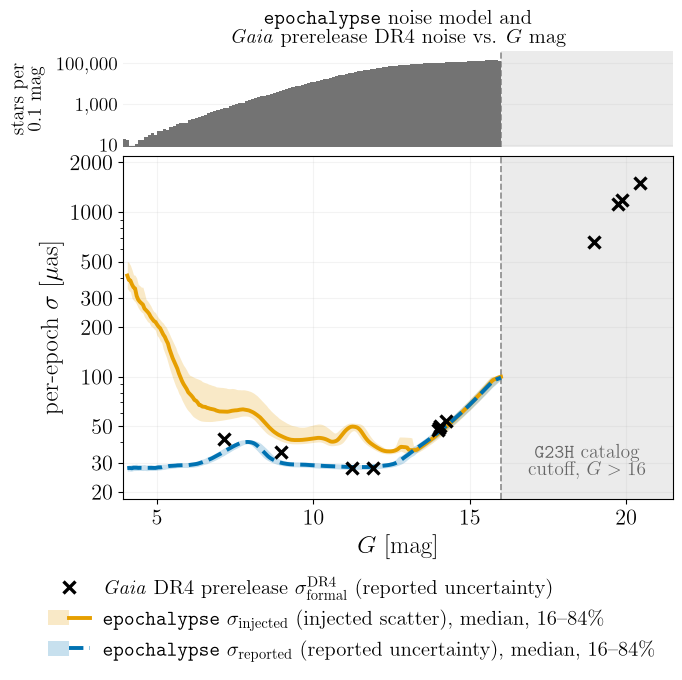

In [11]:
# The paper prints this at \columnwidth (~3.5 in), so the canvas is narrower than the supplementary
# versions and every font is larger; lines and markers are thickened to match. The legend goes
# under the axes, where its long entries fit at this size.
FS2_TITLE, FS2_LABEL, FS2_TICK, FS2_TICK_TOP, FS2_LEGEND, FS2_NOTE = 15, 18, 16, 14, 15, 14
LW2, MS2, MEW2 = 2.8, 9, 2.4
fig = plt.figure(figsize=(6.4, 5.4))
_gs = fig.add_gridspec(2, 1, height_ratios=[1.0, 3.6], hspace=0.04)
ax_top = fig.add_subplot(_gs[0])
ax = fig.add_subplot(_gs[1], sharex=ax_top)

# top: the catalog's stars per 0.1 mag in G
_gb = np.arange(3.0, 16.05, 0.1)
ax_top.hist(_hg[np.isfinite(_hg)], _gb, color="0.45", lw=0, zorder=2)
ax_top.axvspan(16, 21.5, color="0.92", zorder=0)
ax_top.axvline(16, color="0.55", lw=1.2, ls="--", zorder=1)
ax_top.set_yscale("log")
ax_top.set_ylim(8, 4e5)
ax_top.set_yticks([10, 1e3, 1e5])
ax_top.set_yticklabels(["10", "1,000", "100,000"])
ax_top.yaxis.set_minor_formatter(plt.NullFormatter())
ax_top.tick_params(which="both", labelsize=FS2_TICK_TOP, labelbottom=False, length=0)
ax_top.grid(alpha=0.15, which="major", axis="y")
for _side in ("top", "right", "bottom", "left"):
    ax_top.spines[_side].set_visible(False)
ax_top.set_ylabel("stars per" "\n" "0.1 mag", fontsize=FS2_NOTE, labelpad=8)
ax_top.set_title(r"\texttt{epochalypse} noise model and" "\n" r"\textit{Gaia} prerelease DR4 noise vs. $G$ mag",
                 fontsize=FS2_TITLE, linespacing=1.15)
# start the curves where a +-0.25 mag window first holds 60 simulated stars, so no point on them
# is extrapolated from stars brighter than the catalog actually contains
_grid = np.arange(3.2, 16.001, 0.05)
_n_in = np.array([np.diff(np.searchsorted(_G_SORTED, [g - 0.25, g + 0.25]))[0] for g in _grid])
G_CURVE_MIN = float(_grid[np.argmax(_n_in >= 60)])
_grid = _grid[_grid >= G_CURVE_MIN]
print(f"curves drawn from G = {G_CURVE_MIN:.2f} (brightest simulated star G = {np.nanmin(_hg):.2f}; "
      f"{int((_hg < G_CURVE_MIN).sum())} stars brighter than the curve start)")
gcu, medu, lou, hiu = locus("sigma_ueva", grid=_grid)
gcf, medf, lof, hif = locus("sigma_reported_med", grid=_grid)
C_UEVA, C_REP = "#E69F00", "#0072B2"      # Okabe-Ito colour-blind-safe orange and blue
ax.fill_between(gcu, lou * UAS, hiu * UAS, color=C_UEVA, alpha=0.22, lw=0, zorder=2)
ax.fill_between(gcf, lof * UAS, hif * UAS, color=C_REP, alpha=0.22, lw=0, zorder=2)
ax.plot(gcu, medu * UAS, color=C_UEVA, lw=LW2, zorder=3)
ax.plot(gcf, medf * UAS, color=C_REP, lw=LW2, ls="--", zorder=3)
ax.plot(dr4_g, dr4_sigma, **{**marker_kw, "ms": MS2}, mec="k", mew=MEW2, zorder=5)
dress(ax)
ax.set_xlabel("$G$ [mag]", fontsize=FS2_LABEL)
ax.set_ylabel(r"per-epoch $\sigma$ [$\mu$as]", fontsize=FS2_LABEL)
ax.tick_params(which="both", labelsize=FS2_TICK)
for _t in ax.texts:                       # the "beyond the G23H cutoff" note dress() wrote
    _t.set_fontsize(FS2_NOTE)
ax.set_title("")
ax.set_xlim(G_CURVE_MIN - 0.15, 21.5)          # no dead space left of the curve start
handles = [Line2D([0], [0], **{**marker_kw, "ms": MS2}, mec="k", mew=MEW2),
           (Patch(facecolor=C_UEVA, alpha=0.22, edgecolor="none"), Line2D([0], [0], color=C_UEVA, lw=LW2)),
           (Patch(facecolor=C_REP, alpha=0.22, edgecolor="none"), Line2D([0], [0], color=C_REP, lw=LW2, ls="--"))]
labels = [r"\textit{Gaia} DR4 prerelease $\sigma_{\rm formal}^{\rm DR4}$ (reported uncertainty)",
          r"\texttt{epochalypse} $\sigma_{\rm injected}$ (injected scatter), median, 16--84\%",
          r"\texttt{epochalypse} $\sigma_{\rm reported}$ (reported uncertainty), median, 16--84\%"]
ax.legend(handles=handles, labels=labels, loc="upper left", bbox_to_anchor=(-0.15, -0.2), fontsize=FS2_LEGEND,
          handler_map={tuple: HandlerTuple(ndivide=None, pad=0)}, handletextpad=0.6, labelspacing=0.45,
          borderaxespad=0.0, frameon=False)
ax.grid(alpha=0.15, which="major")
fig.subplots_adjust(left=0.12, right=0.98, top=0.94, bottom=0.11)
pf.save(fig, "dr4_prerelease_medians_vs_g", dpi=150, paper=True)
plt.show()
